# Ciekawe zależności w ankiecie · 2026

Sprawdzimy, jak pokrycie pytania o AI zależy od statusu zatrudnienia, które narzędzia są wybierane razem i jak z czasem użycia AI zmienia się deklarowane zaufanie. Porównamy też użyteczność AI i satysfakcję przy siedmiu zadaniach. **pandas** służy do przygotowania grup, tabel i odpowiedzi wielokrotnego wyboru. Skorzystamy też z **mlxtend** do wykrywania reguł współwystępowania oraz **statsmodels** do wyznaczania przedziałów Wilsona.

W JupyterLab wybierz kernel projektu i użyj **Run All**. Zależności instaluje `python -m pip install -r requirements.txt`. Rok w tytule oznacza edycję notatnika.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from mlxtend.frequent_patterns import association_rules, fpgrowth
from scipy.stats.contingency import association
from statsmodels.stats.proportion import proportion_confint

root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "requirements.txt").is_file() and (p / "notebooks").is_dir()),
    None,
)
if root is None:
    raise RuntimeError("Uruchom notatnik z katalogu projektu lub notebooks/.")

task_numbers = range(1, 8)
task_fields = [f"{prefix}_{i}" for prefix in ("AIImpact", "AISat") for i in task_numbers]
fields = ["Employment", "AISelect", "AIDaily", "AITrust", "WorkExp", *task_fields]
responses = pd.read_csv(
    root / "data/raw/survey_results_public.csv", usecols=fields,
    keep_default_na=False, na_values=["", "NA"],
)
for field in fields:
    values = responses[field].astype("string").str.strip()
    responses[field] = values.mask(values.eq(""))
sns.set_theme(style="whitegrid")
print(f"Liczba rekordów w eksporcie: {len(responses):,}")

Liczba rekordów w eksporcie: 30,903


## 1. Kto ma zapisaną odpowiedź o użyciu AI w pracy?

Najpierw sprawdzamy, jak często `AISelect` ma zapis w poszczególnych grupach zatrudnienia. Mianownikiem jest liczba rekordów w danej grupie. Jawne „Nie używam narzędzi AI” liczy się jako odpowiedź. Różnice w pokryciu pomagają zdecydować, których grup użyć do dalszych porównań. Reguły wyświetlania pytania mogą wpływać na te różnice.

Na wykresie długość kolorowego odcinka pokazuje udział grupy z zapisaną odpowiedzią. Liczebność obok nazwy obejmuje całą grupę.

,rekordy,z_zapisem,z_zapisem_%
Employment,,,
Employed,20259,11657,57.5
"Independent contractor, freelancer, or self-employed",4607,2502,54.3
Student,3139,1612,51.4
Not employed,1742,1023,58.7
Retired,607,419,69.0
I prefer not to say,549,251,45.7


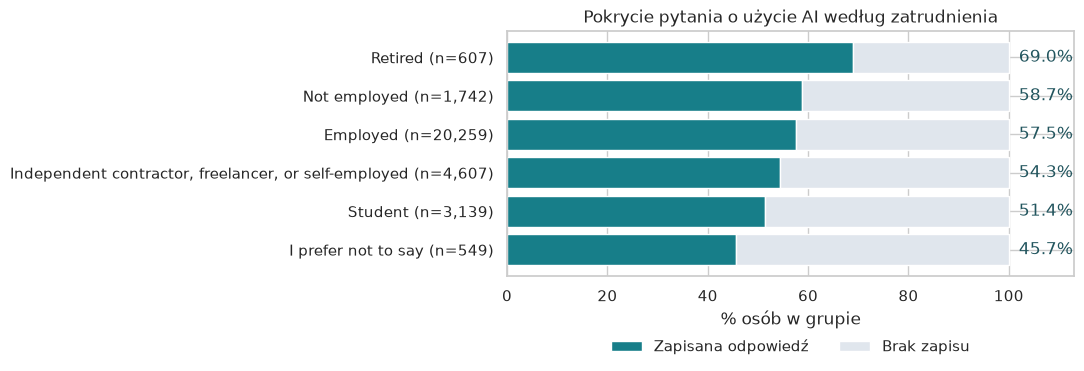

In [2]:
coverage = (
    responses.assign(zapis=responses["AISelect"].notna())
    .groupby("Employment", dropna=False)
    .agg(rekordy=("zapis", "size"), z_zapisem=("zapis", "sum"))
    .sort_values("rekordy", ascending=False)
)
coverage["z_zapisem_%"] = coverage["z_zapisem"].div(coverage["rekordy"]).mul(100)
display(coverage.round(1))

plot_coverage = coverage.sort_values("z_zapisem_%")
recorded_pct = plot_coverage["z_zapisem_%"]
labels = [f"{group} (n={size:,})" for group, size in plot_coverage["rekordy"].items()]
fig, ax = plt.subplots(figsize=(11, 4))
ax.barh(labels, recorded_pct, color="#177e89", label="Zapisana odpowiedź")
ax.barh(labels, 100 - recorded_pct, left=recorded_pct, color="#e0e6ed", label="Brak zapisu")
for i, rate in enumerate(recorded_pct):
    ax.text(102, i, f"{rate:.1f}%", va="center", color="#22555e")
ax.set(xlim=(0, 113), xticks=range(0, 101, 20), xlabel="% osób w grupie",
       title="Pokrycie pytania o użycie AI według zatrudnienia")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
plt.tight_layout()
plt.show()


## 2. Które narzędzia AI wybierane są razem?

Rozbijamy odpowiedzi wielokrotnego wyboru przez `str.split` i `explode`, a następnie odtwarzamy zestaw narzędzi każdej osoby. Analizujemy osoby z co najmniej jednym rozpoznanym typem narzędzia, które nie zaznaczyły równocześnie „Nie używam”. **FP-growth** z biblioteki mlxtend wyszukuje pary obecne u co najmniej 5% analizowanych osób.

Regułę „A → B” czytamy jako odsetek wyborów B wśród osób, które wybrały A. **Lift** dzieli ten odsetek przez częstość wyboru B w całej grupie. Lift 1 oznacza częstość zgodną z niezależnością, a powyżej 1 częstsze współwystępowanie. Reguła opisuje współwybór, bez informacji o kolejności i przyczynie.

Mapa pokazuje każdą parę raz. Kolor oznacza lift, a procent pod nim pokazuje, jaka część analizowanych osób wybrała oba narzędzia. Dzięki temu widać różnicę między parą częstą a parą, która szczególnie często występuje razem względem popularności obu narzędzi.

Podstawa analizy: 14,461 osób z wyborem narzędzia


,A,B,wybrali oba_%,B wśród wybierających A_%,lift
0,Firmowe narzędzia AI,Agenci lub automatyzacje,13.15,61.39,1.94
1,Agenci lub automatyzacje,Firmowe narzędzia AI,13.15,41.60,1.94
2,Agenci lub automatyzacje,Asystenci kodowania,29.73,94.03,1.18
3,Asystenci kodowania,Agenci lub automatyzacje,29.73,37.44,1.18
4,Firmowe narzędzia AI,Asystenci kodowania,18.87,88.09,1.11
5,Asystenci kodowania,Firmowe narzędzia AI,18.87,23.77,1.11
6,Czaty ogólnego przeznaczenia,Agenci lub automatyzacje,25.30,33.74,1.07
7,Agenci lub automatyzacje,Czaty ogólnego przeznaczenia,25.30,80.03,1.07


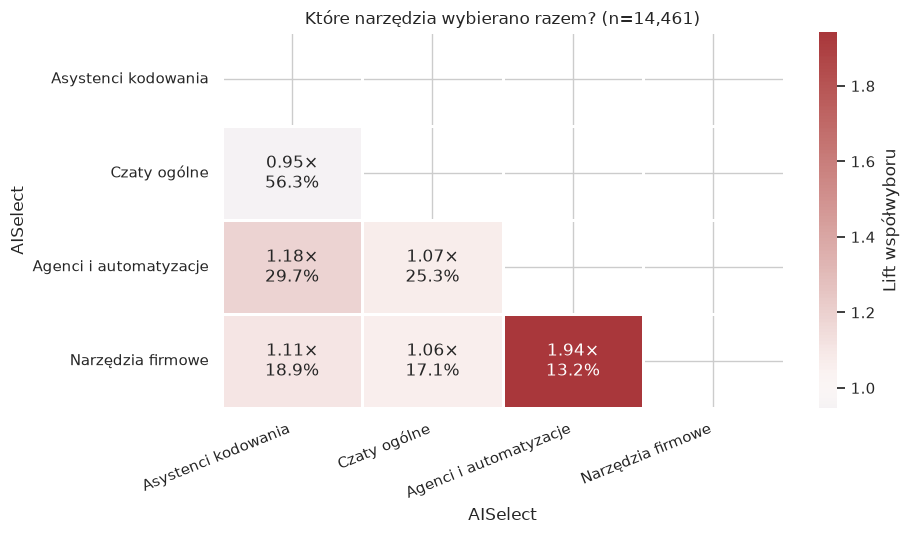

In [3]:
tool_names = {
    "AI coding assistants or coding agents": "Asystenci kodowania",
    "General-purpose AI chat tools": "Czaty ogólnego przeznaczenia",
    "AI agents or automated workflows": "Agenci lub automatyzacje",
    "Internal AI tools built by my company": "Firmowe narzędzia AI",
}
choices = responses["AISelect"].dropna().str.split(";").explode().str.strip()
contradictory = choices.index[choices.eq("I don’t use AI tools")]
tools = choices.loc[choices.isin(tool_names) & ~choices.index.isin(contradictory)]
basket = pd.crosstab(tools.index, tools.map(tool_names)).gt(0)
print(f"Podstawa analizy: {len(basket):,} osób z wyborem narzędzia")
itemsets = fpgrowth(basket, min_support=0.05, use_colnames=True, max_len=2)
rules = association_rules(itemsets, metric="lift", min_threshold=0)
rules = rules.sort_values(["lift", "support"], ascending=False).head(8)
rule_table = pd.DataFrame({
    "A": rules["antecedents"].map(lambda items: next(iter(items))),
    "B": rules["consequents"].map(lambda items: next(iter(items))),
    "wybrali oba_%": 100 * rules["support"],
    "B wśród wybierających A_%": 100 * rules["confidence"],
    "lift": rules["lift"],
})
display(rule_table.reset_index(drop=True).round(2))

tool_order = list(tool_names.values())
flags = basket.reindex(columns=tool_order, fill_value=False).astype(int)
joint = flags.T @ flags / len(flags)
tool_rates = flags.mean()
expected = pd.DataFrame(np.outer(tool_rates, tool_rates), index=tool_order, columns=tool_order)
lift = joint.div(expected.where(expected.gt(0)))
annotations = [
    [f"{lift.loc[a, b]:.2f}×" + chr(10) + f"{joint.loc[a, b]:.1%}" for b in tool_order]
    for a in tool_order
]

fig, ax = plt.subplots(figsize=(9.5, 5.5))
sns.heatmap(lift, mask=np.triu(np.ones(lift.shape, dtype=bool)), annot=annotations, fmt="",
            cmap="vlag", center=1, linewidths=1, cbar_kws={"label": "Lift współwyboru"}, ax=ax)
short_names = ["Asystenci kodowania", "Czaty ogólne", "Agenci i automatyzacje", "Narzędzia firmowe"]
ax.set_xticklabels(short_names, rotation=22, ha="right")
ax.set_yticklabels(short_names, rotation=0)
ax.set_title(f"Które narzędzia wybierano razem? (n={len(flags):,})")
plt.tight_layout()
plt.show()


## 3. Jak czas użycia AI wiąże się z zaufaniem?

Porównujemy cztery kategorie czasu wśród osób z zapisaną odpowiedzią o zaufaniu. Tabela z pandas pokazuje rozkład odpowiedzi, a **V Craméra** z SciPy opisuje siłę związku między dwiema zmiennymi kategorialnymi. Współczynnik bliski zeru oznacza słabszy związek w tej tabeli.

Wykres skupia się na jednej konkretnej odpowiedzi: zaufaniu do AI również przy ważnych decyzjach. **statsmodels** wyznacza 95-procentowe przedziały Wilsona dla odsetków. Pokazują one niepewność przy modelu dwumianowym. Wynik dotyczy tej grupy respondentów i nie uwzględnia mechanizmu doboru próby ani różnic w doświadczeniu czy stanowisku.

V Craméra: 0.183 | Podstawa: 10,007 osób


AITrust,I do not trust it for most work tasks,I trust it for low-risk work tasks only,"I trust it for many tasks, but not important work decisions","I trust it for many tasks, including important work decisions",I trust it when I can easily verify the output,Not sure / I do not use AI tools
AIDaily,,,,,,
Poniżej 1 godziny,14.1,20.9,8.7,1.6,53.9,0.8
1–2 godziny,9.4,18.2,14.9,3.7,53.5,0.3
2–4 godziny,6.2,12.1,23.0,7.1,51.6,0.1
4 godziny lub więcej,7.1,8.5,28.0,17.0,39.2,0.3


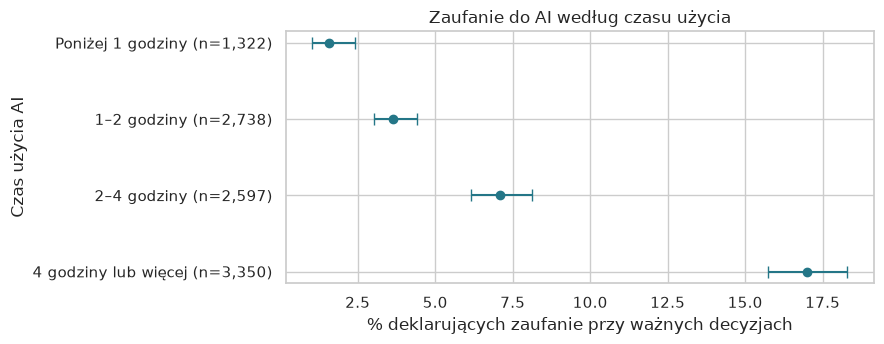

In [4]:
time_labels = {
    "<1 hour every day": "Poniżej 1 godziny",
    "1-2 hours/day": "1–2 godziny",
    "2-4 hours/day": "2–4 godziny",
    "4+ hours/day": "4 godziny lub więcej",
}
trust_sample = responses[["AIDaily", "AITrust"]].dropna()
trust_sample = trust_sample.loc[trust_sample["AIDaily"].isin(time_labels)]
counts = pd.crosstab(trust_sample["AIDaily"], trust_sample["AITrust"]).reindex(
    list(time_labels), fill_value=0
)
group_sizes = counts.sum(axis=1)
counts = counts.loc[group_sizes.gt(0)]
group_sizes = counts.sum(axis=1)
trust_label = "I trust it for many tasks, including important work decisions"
successes = counts.get(trust_label, pd.Series(0, index=counts.index))
rates = successes.div(group_sizes)
low, high = proportion_confint(successes, group_sizes, method="wilson")
cramers_v = association(counts.to_numpy(), method="cramer")
print(f"V Craméra: {cramers_v:.3f} | Podstawa: {group_sizes.sum():,} osób")
display(counts.div(group_sizes, axis=0).mul(100).rename(index=time_labels).round(1))

fig, ax = plt.subplots(figsize=(9, 3.6))
positions = np.arange(len(counts))
ax.errorbar(100 * rates, positions,
            xerr=100 * np.vstack([rates - low, high - rates]).clip(min=0),
            fmt="o", color="#247687", capsize=4)
ax.set_yticks(positions, [f"{time_labels[k]} (n={group_sizes[k]:,})" for k in counts.index])
ax.invert_yaxis()
ax.set(xlabel="% deklarujących zaufanie przy ważnych decyzjach",
       ylabel="Czas użycia AI", title="Zaufanie do AI według czasu użycia")
plt.tight_layout()
plt.show()

## 4. Czy wzorzec zaufania widać też po podziale według stażu?

Dzielimy osoby z sekcji 3 według deklarowanych lat doświadczenia zawodowego. W każdej komórce pokazujemy odsetek osób ufających AI także przy ważnych decyzjach oraz liczebność grupy. Komórki z mniej niż 100 osobami są zasłonięte. Porównuj kolory w obrębie tego samego wiersza, żeby sprawdzić, czy wzorzec według czasu użycia widać wśród osób o podobnym stażu.

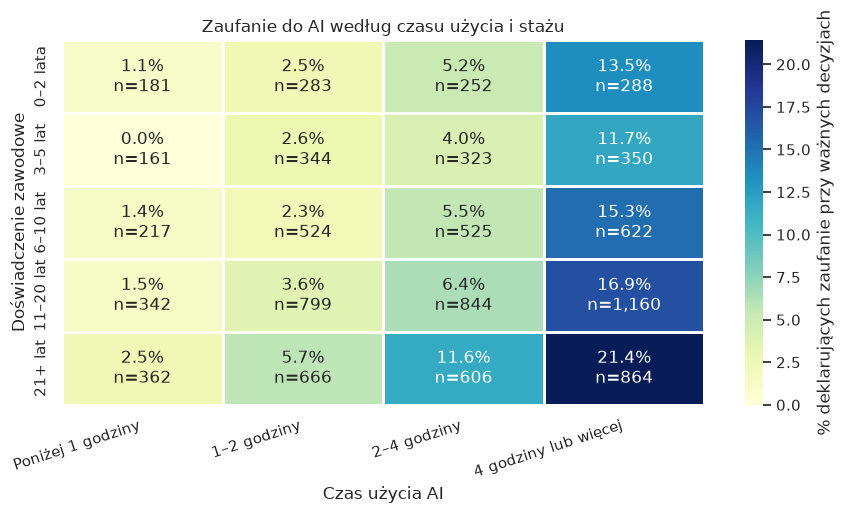

In [5]:
experience = pd.to_numeric(responses.loc[trust_sample.index, "WorkExp"], errors="coerce")
bands = ["0–2 lata", "3–5 lat", "6–10 lat", "11–20 lat", "21+ lat"]
experience_band = pd.cut(experience, bins=[0, 3, 6, 11, 21, np.inf], labels=bands, right=False)
trust_by_experience = (
    trust_sample.assign(staz=experience_band, ufa=trust_sample["AITrust"].eq(trust_label))
    .groupby(["staz", "AIDaily"], observed=True)["ufa"]
    .agg(rekordy="size", udzial="mean")
)
size_grid = trust_by_experience["rekordy"].unstack().reindex(index=bands, columns=time_labels).astype(float)
rate_grid = trust_by_experience["udzial"].unstack().reindex_like(size_grid).astype(float).mul(100)
eligible = size_grid.ge(100)
labels = [
    [f"{rate:.1f}%" + chr(10) + f"n={size:,.0f}" if size >= 100 else ""
     for rate, size in zip(rate_row, size_row, strict=True)]
    for rate_row, size_row in zip(rate_grid.to_numpy(), size_grid.to_numpy(), strict=True)
]
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.set_facecolor("#eeeeee")
sns.heatmap(rate_grid, mask=~eligible, annot=labels, fmt="", cmap="YlGnBu", vmin=0,
            linewidths=1, cbar_kws={"label": "% deklarujących zaufanie przy ważnych decyzjach"}, ax=ax)
ax.set_xticklabels(time_labels.values(), rotation=18, ha="right")
ax.set(ylabel="Doświadczenie zawodowe", xlabel="Czas użycia AI",
       title="Zaufanie do AI według czasu użycia i stażu")
plt.tight_layout()
plt.show()

## 5. Przy których zadaniach użyteczność AI idzie w parze z satysfakcją?

Każdy wiersz porównuje **te same osoby w ramach danego zadania**. Włączamy tylko osoby z dwiema zapisanymi ocenami, a jawne „Nie dotyczy” w pytaniu o użyteczność wyłączamy. Niebieski punkt oznacza odsetek ocen „użyteczne” lub „bardzo użyteczne”. Pomarańczowy pokazuje odsetek osób, które zadeklarowały wzrost satysfakcji z wykonania zadania. Długość odcinka pokazuje różnicę w punktach procentowych, a liczebności mogą się różnić między zadaniami.

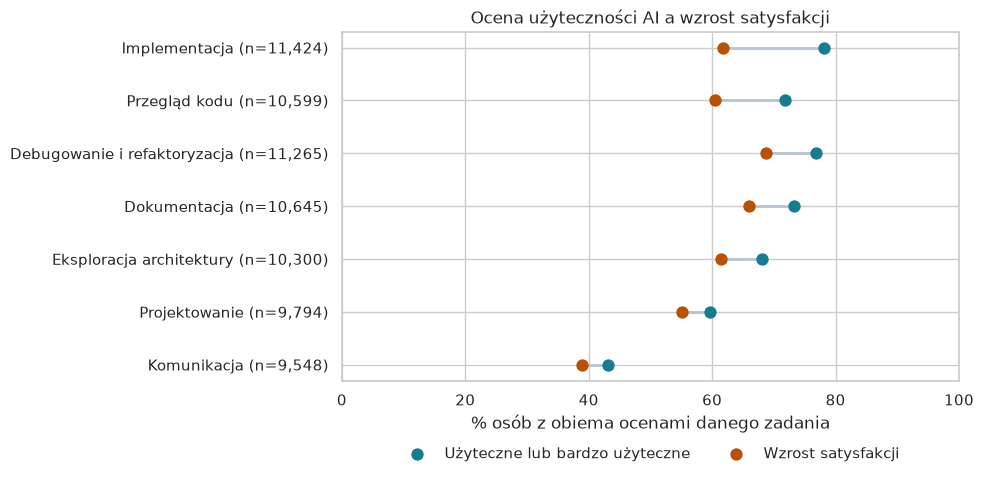

,n,użyteczne,wzrost satysfakcji,różnica_pp
zadanie,,,,
Komunikacja,9548,43.1,38.9,4.3
Projektowanie,9794,59.7,55.1,4.5
Eksploracja architektury,10300,68.1,61.4,6.7
Dokumentacja,10645,73.3,66.0,7.3
Debugowanie i refaktoryzacja,11265,76.9,68.7,8.2
Przegląd kodu,10599,71.9,60.4,11.5
Implementacja,11424,78.2,61.8,16.4


In [6]:
task_labels = [
    "Projektowanie", "Implementacja", "Przegląd kodu", "Debugowanie i refaktoryzacja",
    "Dokumentacja", "Eksploracja architektury", "Komunikacja",
]
rows = []
for number, task in zip(task_numbers, task_labels, strict=True):
    impact, satisfaction = f"AIImpact_{number}", f"AISat_{number}"
    paired = responses[[impact, satisfaction]].dropna()
    paired = paired.loc[paired[impact].ne("Not applicable")]
    rows.append({
        "zadanie": task,
        "n": len(paired),
        "użyteczne": paired[impact].isin(["Useful", "Very useful"]).mean() * 100,
        "wzrost satysfakcji": paired[satisfaction].isin(["Somewhat improved", "Greatly improved"]).mean() * 100,
    })
tasks = pd.DataFrame(rows).set_index("zadanie")
tasks["różnica_pp"] = tasks["użyteczne"] - tasks["wzrost satysfakcji"]
tasks = tasks.sort_values("różnica_pp")

fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(tasks))
ax.hlines(y, tasks[["użyteczne", "wzrost satysfakcji"]].min(axis=1),
          tasks[["użyteczne", "wzrost satysfakcji"]].max(axis=1), color="#b8c3d0", linewidth=2)
ax.scatter(tasks["użyteczne"], y, color="#147d92", s=62, label="Użyteczne lub bardzo użyteczne", zorder=3)
ax.scatter(tasks["wzrost satysfakcji"], y, color="#b95100", s=62, label="Wzrost satysfakcji", zorder=3)
ax.set_yticks(y, [f"{task} (n={size:,})" for task, size in tasks["n"].items()])
ax.set(xlim=(0, 100), xlabel="% osób z obiema ocenami danego zadania",
       title="Ocena użyteczności AI a wzrost satysfakcji")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.tight_layout()
plt.show()
display(tasks.round(1))

## 6. Co zbadać dalej?

Podsumowanie pobiera wyniki z tabel powyżej i wskazuje kierunki dalszej analizy. Każdy dotyczy innego pytania badawczego i ma określoną grupę odniesienia.

In [7]:
strongest = rule_table.iloc[0]
largest_gap = tasks["różnica_pp"].abs().idxmax()
display(Markdown(
    f"- **Współwybór narzędzi.** Para „{strongest['A']}” i „{strongest['B']}” "
    f"ma lift **{strongest['lift']:.2f}**. Sprawdź, czy podobny wzorzec utrzymuje się "
    "osobno w grupach o różnych rolach i poziomach doświadczenia.\n"
    f"- **Czas i zaufanie.** W tej grupie V Craméra wynosi **{cramers_v:.3f}**. "
    "Porównaj rozkłady zaufania po wydzieleniu podobnych grup zawodowych i stażu. "
    "Raportuj liczebności każdej podgrupy.\n"
    "- **Dobór grupy.** Przed porównaniem adopcji AI między grupami zatrudnienia "
    "zestaw pokrycie pytania i udział jawnych odpowiedzi „Nie używam” wśród osób z zapisem. "
    "To pozwoli odróżnić słabą obserwowalność pytania od niskiej deklarowanej adopcji."
))

display(Markdown(
    f"- **Użyteczność a satysfakcja.** Największa różnica wystąpiła dla zadania "
    f"„{largest_gap}” (**{abs(tasks.loc[largest_gap, 'różnica_pp']):.1f} p.p.**). "
    "W kolejnej analizie sprawdź, ile osób oceniło AI jako użyteczne, "
    "jednocześnie deklarując brak poprawy satysfakcji."
))


- **Współwybór narzędzi.** Para „Firmowe narzędzia AI” i „Agenci lub automatyzacje” ma lift **1.94**. Sprawdź, czy podobny wzorzec utrzymuje się osobno w grupach o różnych rolach i poziomach doświadczenia.
- **Czas i zaufanie.** W tej grupie V Craméra wynosi **0.183**. Porównaj rozkłady zaufania po wydzieleniu podobnych grup zawodowych i stażu. Raportuj liczebności każdej podgrupy.
- **Dobór grupy.** Przed porównaniem adopcji AI między grupami zatrudnienia zestaw pokrycie pytania i udział jawnych odpowiedzi „Nie używam” wśród osób z zapisem. To pozwoli odróżnić słabą obserwowalność pytania od niskiej deklarowanej adopcji.

- **Użyteczność a satysfakcja.** Największa różnica wystąpiła dla zadania „Implementacja” (**16.4 p.p.**). W kolejnej analizie sprawdź, ile osób oceniło AI jako użyteczne, jednocześnie deklarując brak poprawy satysfakcji.